# Comparación de escenarios: base vs geo vs extendido

Consolida las tablas generadas por los notebooks anteriores y produce la tabla final de la entrega.

**Entradas (se generan en orden):**

- `reports/comparacion_base.csv` ← `notebooks/evaluation/01_evaluacion_modelos.ipynb`
- `reports/comparacion_features.csv` ← `notebooks/evaluation/02_evaluacion_modelos_features.ipynb`
- `reports/ext_comparacion_modelos.csv` ← `notebooks/models_features_ext/01_modelos_extendido.ipynb`
- `reports/lightgbm_ext_tuned_metricas.csv` ← `notebooks/models_features_ext/02_tuning_extendido.ipynb`

**Salidas:** `reports/comparacion_escenarios.csv`, `reports/comparacion_escenarios_pivot.csv`, `reports/comparacion_deltas.csv`, figuras y un resumen Markdown.

In [2]:
import sys
sys.path.append('../..')

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.utils import REPORTS_DIR

sns.set_theme(style='whitegrid')
COLUMNAS = ['escenario', 'modelo', 'accuracy', 'balanced_accuracy', 'f1_macro', 'f1_weighted', 'accuracy_adjacent', 'mae_ordinal', 'qwk']

In [3]:
rutas = {
    'base': REPORTS_DIR / 'comparacion_base.csv',
    'geo': REPORTS_DIR / 'comparacion_features.csv',
    'extendido': REPORTS_DIR / 'ext_comparacion_modelos.csv',
    'extendido_tuning': REPORTS_DIR / 'lightgbm_ext_tuned_metricas.csv',
    'extendido_ensemble': REPORTS_DIR / 'ensemble_ext_metricas.csv',
}

partes = []
for escenario, ruta in rutas.items():
    if not ruta.exists():
        print('Falta (se omite):', ruta.name)
        continue
    tabla = pd.read_csv(ruta)
    if 'escenario' not in tabla.columns:
        tabla['escenario'] = escenario
    else:
        tabla['escenario'] = tabla['escenario'].fillna(escenario)
    partes.append(tabla)

if not partes:
    raise FileNotFoundError('No hay tablas de métricas. Ejecuta los notebooks de evaluación anteriores.')

comparacion = pd.concat(partes, ignore_index=True, sort=False)
for columna in COLUMNAS:
    if columna not in comparacion.columns:
        comparacion[columna] = float('nan')

comparacion['familia'] = (
    comparacion['modelo']
    .str.replace('_features', '', regex=False)
    .str.replace('_ext_tuned', '', regex=False)
    .str.replace('_ext', '', regex=False)
    .str.replace('_tuned', '', regex=False)
)

comparacion = comparacion[COLUMNAS + ['familia']]
comparacion.to_csv(REPORTS_DIR / 'comparacion_escenarios.csv', index=False)
print('Escenarios disponibles:', sorted(comparacion['escenario'].unique()))
display(comparacion.sort_values(['escenario', 'f1_macro'], ascending=[True, False]))

Escenarios disponibles: ['base', 'extendido', 'extendido_ensemble', 'extendido_tuning', 'geo']


,escenario,modelo,accuracy,balanced_accuracy,f1_macro,f1_weighted,accuracy_adjacent,mae_ordinal,qwk,familia
0,base,lightgbm,0.688305,0.687959,0.686526,0.686808,0.970681,0.346641,0.830649,lightgbm
1,base,random_forest,0.681381,0.680992,0.677917,0.678220,0.965812,0.358758,0.823332,random_forest
2,base,xgboost,0.671102,0.670730,0.668548,0.668846,0.966245,0.368495,0.818655,xgboost
3,base,ordinal_logistic,0.625446,0.625183,0.627935,0.628221,0.967327,0.412096,0.795091,ordinal_logistic
8,extendido,lightgbm_ext,0.729741,0.729438,0.728812,0.729075,0.978362,0.295575,0.859333,lightgbm
9,extendido,xgboost_ext,0.724224,0.723926,0.723944,0.724206,0.978795,0.300660,0.856802,xgboost
10,extendido,random_forest_ext,0.711674,0.711359,0.710139,0.710391,0.971330,0.323163,0.839313,random_forest
11,extendido,ordinal_logistic_ext,0.673807,0.673581,0.676780,0.677050,0.977280,0.351834,0.831965,ordinal_logistic
13,extendido_ensemble,ensemble_ext,0.730282,0.729984,0.729466,0.729722,0.978795,0.294601,0.859895,ensemble
12,extendido_tuning,lightgbm_ext_tuned,0.728335,0.728046,0.727782,0.728038,0.979552,0.295575,0.860228,lightgbm


In [4]:
pivot_f1 = comparacion.pivot_table(
    index='familia', columns='escenario', values='f1_macro', aggfunc='max'
)
pivot_acc = comparacion.pivot_table(
    index='familia', columns='escenario', values='accuracy', aggfunc='max'
)
pivot_adj = comparacion.pivot_table(
    index='familia', columns='escenario', values='accuracy_adjacent', aggfunc='max'
)

pivot_f1.to_csv(REPORTS_DIR / 'comparacion_escenarios_pivot.csv')
display(pivot_f1)
display(pivot_acc)
display(pivot_adj)

escenario,base,extendido,extendido_ensemble,extendido_tuning,geo
familia,,,,,
ensemble,NaN,NaN,0.729466,NaN,NaN
lightgbm,0.686526,0.728812,NaN,0.727782,0.689235
ordinal_logistic,0.627935,0.676780,NaN,NaN,0.641959
random_forest,0.677917,0.710139,NaN,NaN,0.684603
xgboost,0.668548,0.723944,NaN,NaN,0.678050


escenario,base,extendido,extendido_ensemble,extendido_tuning,geo
familia,,,,,
ensemble,NaN,NaN,0.730282,NaN,NaN
lightgbm,0.688305,0.729741,NaN,0.728335,0.690577
ordinal_logistic,0.625446,0.673807,NaN,NaN,0.639511
random_forest,0.681381,0.711674,NaN,NaN,0.687006
xgboost,0.671102,0.724224,NaN,NaN,0.679758


escenario,base,extendido,extendido_ensemble,extendido_tuning,geo
familia,,,,,
ensemble,NaN,NaN,0.978795,NaN,NaN
lightgbm,0.970681,0.978362,NaN,0.979552,0.970464
ordinal_logistic,0.967327,0.977280,NaN,NaN,0.969274
random_forest,0.965812,0.971330,NaN,NaN,0.966894
xgboost,0.966245,0.978795,NaN,NaN,0.969274


In [5]:
deltas = pd.DataFrame(index=pivot_f1.index)
if {'base', 'geo'} <= set(pivot_f1.columns):
    deltas['delta_geo_base'] = pivot_f1['geo'] - pivot_f1['base']
if {'base', 'extendido'} <= set(pivot_f1.columns):
    deltas['delta_ext_base'] = pivot_f1['extendido'] - pivot_f1['base']
if {'extendido', 'extendido_tuning'} <= set(pivot_f1.columns):
    deltas['delta_tuning_ext'] = (
        pivot_f1['extendido_tuning'] - pivot_f1['extendido']
    )

deltas.to_csv(REPORTS_DIR / 'comparacion_deltas.csv')
display(deltas)

,delta_geo_base,delta_ext_base,delta_tuning_ext
familia,,,
ensemble,NaN,NaN,NaN
lightgbm,0.002709,0.042286,-0.00103
ordinal_logistic,0.014024,0.048845,NaN
random_forest,0.006686,0.032222,NaN
xgboost,0.009502,0.055396,NaN


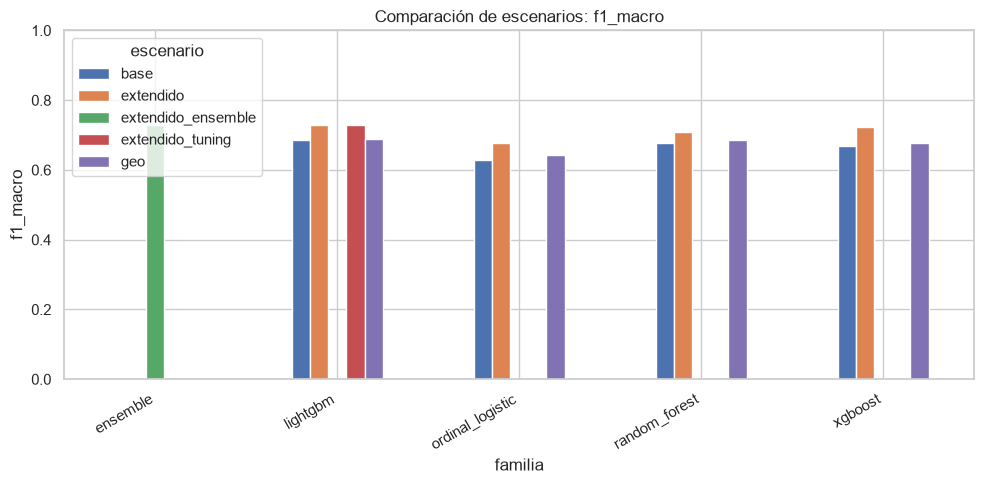

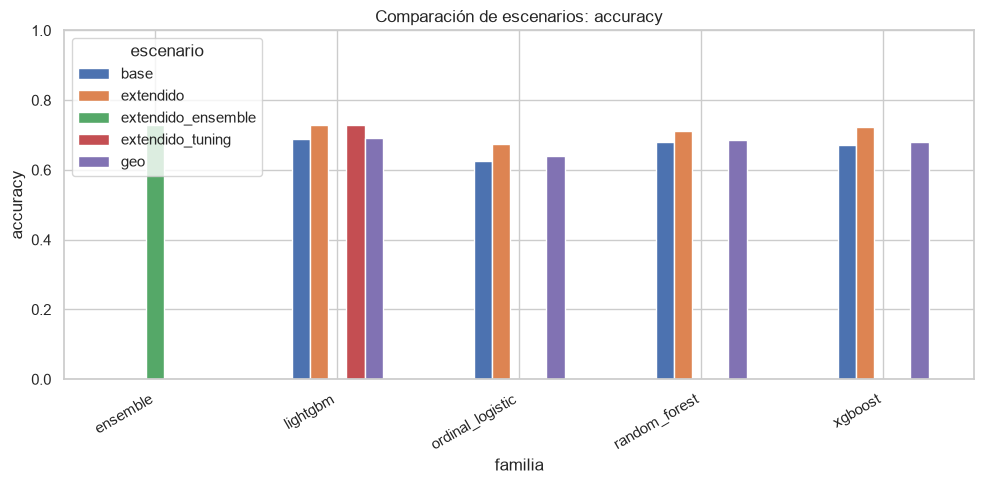

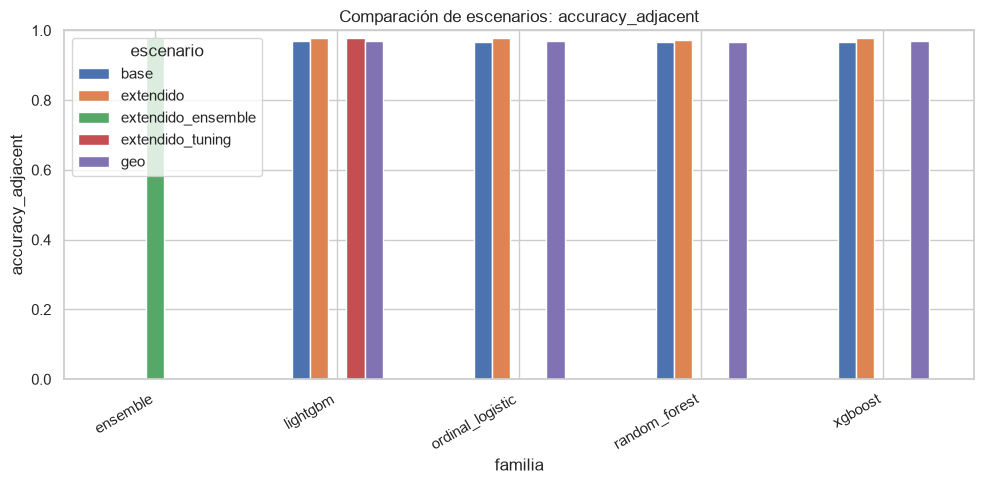

In [6]:
for nombre, pivot in [
    ('f1_macro', pivot_f1),
    ('accuracy', pivot_acc),
    ('accuracy_adjacent', pivot_adj),
]:
    if pivot.dropna(how='all').empty:
        continue
    pivot.plot(kind='bar', figsize=(10, 5))
    plt.title(f'Comparación de escenarios: {nombre}')
    plt.ylabel(nombre)
    plt.ylim(0, 1)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(
        REPORTS_DIR / f'comparacion_escenarios_{nombre}.png',
        dpi=150,
        bbox_inches='tight',
    )
    plt.show()

In [7]:
mejor_por_escenario = comparacion.loc[
    comparacion.groupby('escenario')['f1_macro'].idxmax()
].sort_values('f1_macro', ascending=False)
mejor_por_escenario.to_csv(REPORTS_DIR / 'comparacion_mejor_por_escenario.csv', index=False)
display(mejor_por_escenario[['escenario', 'modelo', 'accuracy', 'f1_macro', 'accuracy_adjacent', 'qwk']])

mejor_global = mejor_por_escenario.iloc[0]
print('Mejor modelo global:', mejor_global['modelo'])
print('Accuracy exacta:', round(float(mejor_global['accuracy']), 4))
print('Accuracy adyacente:', round(float(mejor_global['accuracy_adjacent']), 4))

,escenario,modelo,accuracy,f1_macro,accuracy_adjacent,qwk
13,extendido_ensemble,ensemble_ext,0.730282,0.729466,0.978795,0.859895
8,extendido,lightgbm_ext,0.729741,0.728812,0.978362,0.859333
12,extendido_tuning,lightgbm_ext_tuned,0.728335,0.727782,0.979552,0.860228
4,geo,lightgbm_features,0.690577,0.689235,0.970464,0.830026
0,base,lightgbm,0.688305,0.686526,0.970681,0.830649


Mejor modelo global: ensemble_ext
Accuracy exacta: 0.7303
Accuracy adyacente: 0.9788


In [8]:
lineas = [
    '# Comparación de escenarios AirPrice',
    '',
    'Tabla de F1-Macro por familia de modelo y escenario:',
    '',
    '```text',
    pivot_f1.to_string(),
    '```',
    '',
    'Tabla de accuracy exacta:',
    '',
    '```text',
    pivot_acc.to_string(),
    '```',
    '',
    'Tabla de accuracy adyacente (acierto exacto o en la clase vecina):',
    '',
    '```text',
    pivot_adj.to_string(),
    '```',
    '',
    '## Mejor modelo por escenario',
    '',
    '```text',
    mejor_por_escenario[['escenario', 'modelo', 'accuracy', 'f1_macro', 'accuracy_adjacent', 'qwk']].to_string(index=False),
    '```',
    '',
    '## Lectura',
    '',
]

if 'base' in pivot_f1.columns and 'geo' in pivot_f1.columns:
    lineas.append(
        '- El delta geo-base es pequeño si las distancias y los clusters no aportan información nueva: `latitude`, `longitude` y `neighbourhood_cleansed` ya estaban en la baseline.'
    )
if 'extendido' in pivot_f1.columns:
    lineas.append(
        '- El escenario extendido añade amenidades, review scores, disponibilidad, portafolio del host y densidad. Es el mejor esfuerzo para acercarse al 90 %.'
    )
lineas.extend(
    [
        '- La accuracy exacta de 4 clases ordinales tiene un techo práctico: los cortes de precio son cuantiles y los anuncios cercanos a un límite son ambiguos.',
        '- `accuracy_adjacent` es la métrica ordinal relevante. Si supera 0.90, el modelo cumple el objetivo de negocio aunque la accuracy exacta no llegue a 0.90.',
        '- El test se usó una sola vez por modelo; la selección de hiperparámetros se hizo en validación.',
    ]
)

ruta_reporte = REPORTS_DIR / 'comparacion_escenarios.md'
ruta_reporte.write_text('\n'.join(lineas), encoding='utf-8')
print('Reporte guardado en:', ruta_reporte)
print('\n'.join(lineas))

Reporte guardado en: D:\Universidad\ElectivaCienciasComputacion2\Proyecto\AirPrice\reports\comparacion_escenarios.md
# Comparación de escenarios AirPrice

Tabla de F1-Macro por familia de modelo y escenario:

```text
escenario             base  extendido  extendido_ensemble  extendido_tuning       geo
familia                                                                              
ensemble               NaN        NaN            0.729466               NaN       NaN
lightgbm          0.686526   0.728812                 NaN          0.727782  0.689235
ordinal_logistic  0.627935   0.676780                 NaN               NaN  0.641959
random_forest     0.677917   0.710139                 NaN               NaN  0.684603
xgboost           0.668548   0.723944                 NaN               NaN  0.678050
```

Tabla de accuracy exacta:

```text
escenario             base  extendido  extendido_ensemble  extendido_tuning       geo
familia                                                

## Cómo interpretar la tabla final

- **Base:** 32 variables del ETL original. Referencia: LightGBM ≈ 0.688 de accuracy exacta.
- **Geo:** base + 6 variables geoespaciales (5 distancias + `cluster_zona`). Mismo preprocesador, mismo split y mismos hiperparámetros.
- **Extendido:** recupera variables del original y agrega geo adicional. No es estrictamente comparable con base/geo porque cambia el conjunto de features; es el escenario de mejor esfuerzo.
- **Extendido + tuning:** mejor configuración de LightGBM seleccionada por validación cruzada, con comparación de target encoding y `class_weight`.

### Sobre el objetivo de 0.90

Con exactitud de 4 clases ordinales, 0.90 es un objetivo muy exigente para datos tabulares de Airbnb. La razón principal es que el target se construyó discretizando el precio en cuantiles: dos anuncios con precio 178 y 182 caen en clases distintas, pero son casi idénticos en sus features. Un modelo perfectamente razonable puede confundirlos. Por eso se reporta `accuracy_adjacent` y `qwk`: miden si el error es grave (ECONOMICO↔PREMIUM) o leve (clases vecinas).

Si la accuracy exacta no alcanza 0.90, la entrega debe documentar el mejor esfuerzo, la curva de mejora por escenario y la justificación del techo práctico.